## Introduzione al progetto
 
 I mercati finanziari generano ogni giorno una grande quantità di dati, come i prezzi di apertura, chiusura, volumi di scambio e
 variazioni percentuali. Analizzare questi dati manualmente è complesso, ma le tecniche di Machine Learning permettono di individuare
 pattern  e relazioni utili per effettuare previsioni.

 L'obiettivo di questo progetto è applicare algoritmi di Machine Learning per predire la direzione del prezzo di un'azione,
 utilizzando dati storici reali. In particolare, il modello che cercherà di prevedere se il prezzo di chiusura di un'azione aumenterà
 o diminuirà nel giorno successivo, trasformando il problema in un task di classificazione binaria.

 Per svolgere questa analisi verranno utilizzati dati finanziari storici scaricati tramite la libreria Python /yfinance.
 Successivamente, i dati verranno preprocessati per creare le feature di input e la variabile target. Verrano quindi addrestati
 e confrontati diversi algoritmi di Machine Learning, tra cui Logistic Regression e Random Forest.

 Infine, le performance dei modelli veranno valutate utilizzando metriche di classificazione come l'accuracy e la confusion matrix, 
 al fine di determinare quale algoritmo sia più efficace nella predizione della direzione del prezzo azionario.

 Questo progetto dimostra come le tecniche di Machine Learning possono essere applicate a problemi reali nel contesto finanziario, evidenziando sia le potenzialità che i limiti di questi approcci.

In [1]:
!pip install yfinance 
!pip install matplotlib scikit-learn pandas numpy
!pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import delle librerie necessarie
import yfinance as yf
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

## Caricamento dei dati

I dati utilizzati nel progetto sono stati scaricati tramite la libreria yfinance, che consente di ottenere serie storiche finanziarie da Yahoo Finance.

In particolare, è stato selezionato il titolo Apple (AAPL) nel periodo compreso tra il 2018 e il 2024. Il dataset include informazioni giornaliere come prezzo di apertura, massimo, minimo, chiusura e volume.

In [3]:
# Scarico dati azioni Apple

data = yf.download("AAPL", start="2018-01-01", end="2024-01-01")

#Mostro le prime righe

(data.head())

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2018-01-02,40.232376,40.241720,39.531708,39.741910,102223600
2018-01-03,40.225368,40.767220,40.162311,40.295436,118071600
2018-01-04,40.412209,40.514974,40.190331,40.297765,89738400
2018-01-05,40.872318,40.958733,40.416885,40.507971,94640000
2018-01-08,40.720501,41.014780,40.622404,40.720501,82271200


## Espolrazione del dataset

In questa fase viene effettuata un’analisi preliminare del dataset, osservando la struttura dei dati, il numero di osservazioni e alcune statistiche descrittive.

Questa analisi permette di comprendere meglio le caratteristiche delle variabili e individuare eventuali problemi nei dati.

In [4]:
#Dimensioni del dataset
print("Shape: ", data.shape)

#Info colonne
data.info()

#Statistiche base
data.describe()

Shape:  (1509, 5)
<class 'pandas.DataFrame'>
DatetimeIndex: 1509 entries, 2018-01-02 to 2023-12-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1509 non-null   float64
 1   (High, AAPL)    1509 non-null   float64
 2   (Low, AAPL)     1509 non-null   float64
 3   (Open, AAPL)    1509 non-null   float64
 4   (Volume, AAPL)  1509 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 70.7 KB


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,1509.000000,1509.000000,1509.000000,1509.000000,1.509000e+03
mean,107.531711,108.656291,106.294922,107.432027,1.073284e+08
std,50.795831,51.268348,50.269725,50.754968,5.513287e+07
min,33.707928,34.544758,33.662885,34.132268,2.404830e+07
25%,51.098343,51.899184,50.720358,51.235351,7.078370e+07
50%,120.137726,121.388395,118.642662,120.278143,9.296430e+07
75%,149.813004,151.559924,147.820882,149.639080,1.280440e+08
max,195.723816,197.215623,194.627166,195.634904,4.265100e+08


## Features

Per arricchire il dataset aggiungiamo alcune feature derivate. In particolare:

1. il rendimento giornaliero,
2. la media mobile a 10 giorni,
3. la media mobile a 50 giorni,
4. la volatilità a 10 giorni,
5. il momentum a 5 giorni.

Questi indicatori tecnici aiutano il modello a catturare meglio l’andamento del mercato.

In [5]:
# Rendimento giornaliero
data["Return"] = data["Close"].pct_change()

# Medie mobili
data["MA10"] = data["Close"].rolling(10).mean()
data["MA50"] = data["Close"].rolling(50).mean()

# Volatilità
data["Volatility"] = data["Return"].rolling(10).std()

# Momentum
data["Momentum"] = data["Close"] - data["Close"].shift(5)

## Creazione del target

La variabile target vale 1 se il prezzo di chiusura del giorno successivo è maggiore di quello corrente, e 0 altrimenti. In questo modo il problema viene formulato come classificazione binaria: prevedere se il titolo salirà o scenderà il giorno dopo.

In [6]:
data["Target"] = (data["Close"].shift(-1) > data["Close"]).astype(int)
data = data.dropna()
data.head()

Price,Close,High,Low,Open,Volume,Return,MA10,MA50,Volatility,Momentum,Target
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,
Date,,,,,,,,,,,
2018-03-14,41.845676,42.333454,41.697935,42.286553,117473600,-0.008501,41.666977,40.322699,0.011184,0.799671,1
2018-03-15,41.894901,42.267772,41.758890,41.859726,90975200,0.001176,41.752570,40.355950,0.009288,0.400986,0
2018-03-16,41.747177,42.005134,41.653372,41.894915,157618800,-0.003526,41.795016,40.386386,0.009275,-0.459625,0
2018-03-19,41.109310,41.618193,40.724717,41.583018,133787200,-0.015279,41.759370,40.400328,0.010542,-1.505539,0
2018-03-20,41.095249,41.461082,41.024896,41.095249,78597600,-0.000342,41.725836,40.404787,0.010543,-1.109226,0


## Definizione di X e y

Definiamo la matrice delle feature X e il vettore target y. Oltre alle variabili originali del dataset, includiamo anche gli indicatori tecnici creati in precedenza.

In [7]:
features = ["Open", "High", "Low", "Close", "Volume", "MA10", "MA50", "Volatility", "Momentum"]

X = data[features]
y = data["Target"]

## Suddivisione train/test temporale

Poiché si tratta di una serie temporale, la divisione tra training set e test set viene effettuata rispettando l’ordine cronologico dei dati. Questa scelta è più corretta rispetto a una divisione casuale, che introdurrebbe informazioni future nel training

In [8]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

## Baseline semplice

Introduciamo una baseline molto semplice, che prevede sempre un rialzo del prezzo. Questo confronto è utile per verificare se i modelli di machine learning ottengono risultati realmente migliori di una strategia banale.

In [9]:
baseline_pred = np.ones(len(y_test), dtype=int)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline accuracy:", baseline_accuracy)

Baseline accuracy: 0.5376712328767124


## Logistic Regression

Alleniamo un modello di Logistic Regression, uno dei metodi più semplici e interpretabili per problemi di classificazione binaria. Successivamente valutiamo la sua accuratezza sul test set.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)

log_accuracy = accuracy_score(y_test, log_pred)

print("Accuracy Logistic Regression:", log_accuracy)

Accuracy Logistic Regression: 0.5513698630136986


## Random Forest

Alleniamo anche un modello Random Forest, basato su un insieme di alberi decisionali. Questo approccio è spesso più flessibile della regressione logistica e può catturare relazioni non lineari tra le variabili.

In [11]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Accuracy Random Forest:", rf_accuracy)

Accuracy Random Forest: 0.5205479452054794


## Suport Vector Machine

Addestriamo un modello SVM con kernel RBF, particolarmente adatto 
quando i dati non sono linearmente separabili. Prima dell'addestramento 
le feature vengono normalizzate tramite StandardScaler, 
necessario per le prestazioni ottimali della SVM.

In [12]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Accuracy SVM:", svm_accuracy)

Accuracy SVM: 0.5


## Confronto dei risultati

Visualizziamo in un grafico le accuracy ottenute dai diversi approcci, in modo da confrontare immediatamente le performance dei modelli rispetto alla baseline.

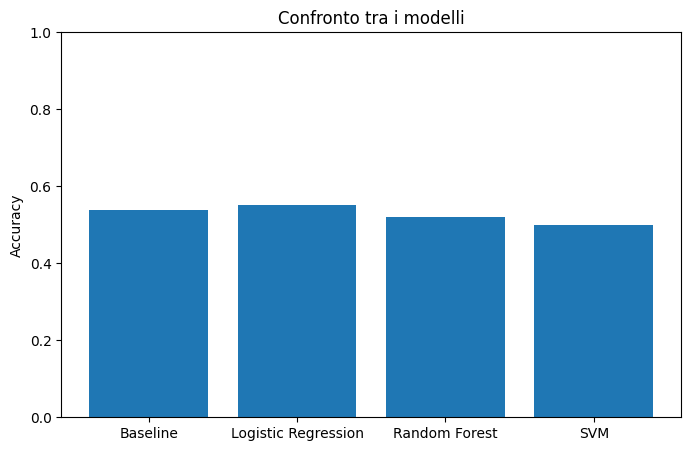

In [13]:
models = ["Baseline", "Logistic Regression", "Random Forest", "SVM"]
scores = [baseline_accuracy, log_accuracy, rf_accuracy, svm_accuracy]

plt.figure(figsize=(8,5))
plt.bar(models, scores)
plt.ylabel("Accuracy")
plt.title("Confronto tra i modelli")
plt.ylim(0, 1)
plt.show()

## Confusion matrix

Le confusion matrix permettono di osservare in modo più dettagliato il comportamento dei modelli, mostrando quante volte la previsione è corretta o errata per ciascuna classe.

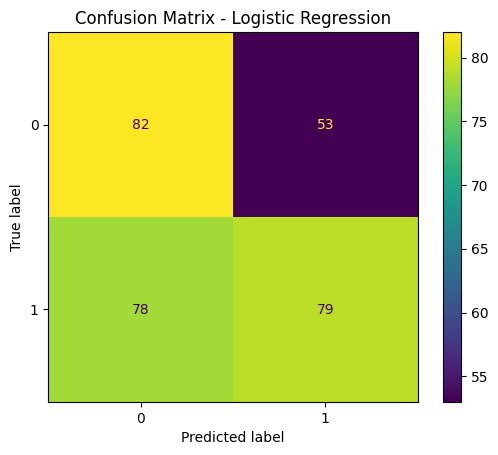

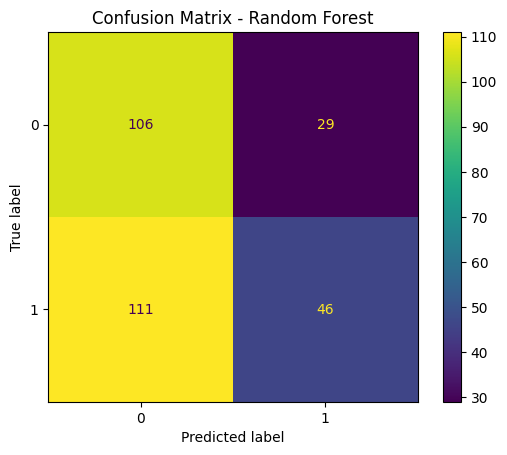

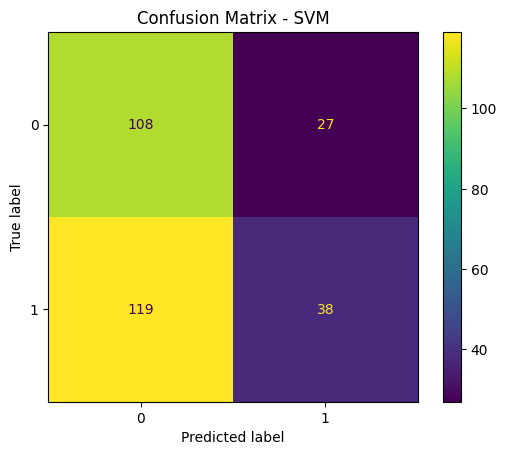

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, log_pred)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)
plt.title("Confusion Matrix - Random Forest")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, svm_pred)
plt.title("Confusion Matrix - SVM")
plt.show()

In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_test, baseline_pred))

print("=== Logistic Regression ===")
print(classification_report(y_test, log_pred))

print("=== SVM ===")
print(classification_report(y_test, svm_pred))

print("=== Random Forest ===")
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       135
           1       0.54      1.00      0.70       157

    accuracy                           0.54       292
   macro avg       0.27      0.50      0.35       292
weighted avg       0.29      0.54      0.38       292

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.51      0.61      0.56       135
           1       0.60      0.50      0.55       157

    accuracy                           0.55       292
   macro avg       0.56      0.56      0.55       292
weighted avg       0.56      0.55      0.55       292

=== SVM ===
              precision    recall  f1-score   support

           0       0.48      0.80      0.60       135
           1       0.58      0.24      0.34       157

    accuracy                           0.50       292
   macro avg       0.53      0.52      0.47       292
weighted avg       0.53      0.50 

C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

## Predizione di prezzi tramite la Random Forest

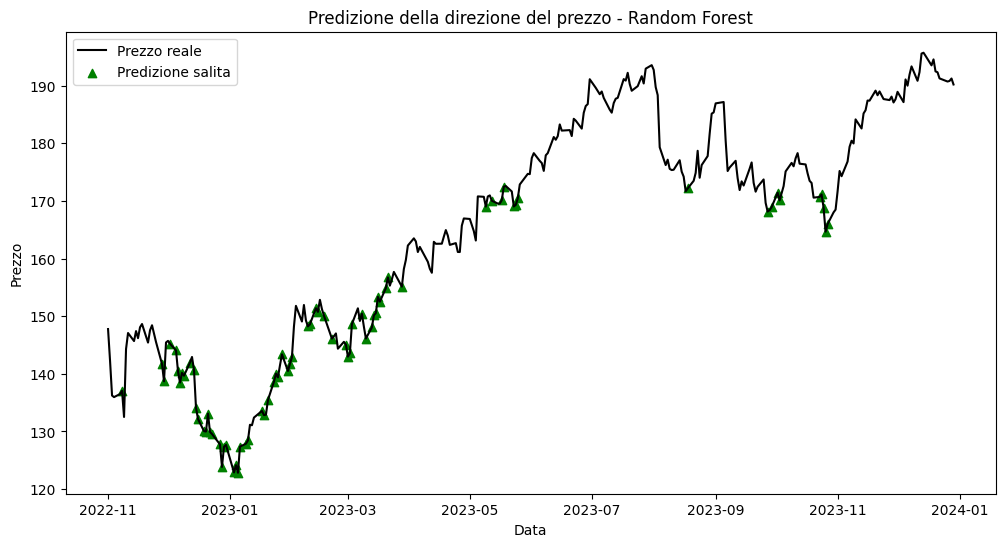

In [16]:
results = data.iloc[split:].copy()
results["Prediction"] = rf_pred

plt.figure(figsize=(12,6))

plt.plot(results.index, results["Close"], label="Prezzo reale", color="black")

buy_signals = results[results["Prediction"] == 1]

plt.scatter(buy_signals.index, buy_signals["Close"],
            color="green", label="Predizione salita", marker="^")

plt.title("Predizione della direzione del prezzo - Random Forest")
plt.xlabel("Data")
plt.ylabel("Prezzo")
plt.legend()

plt.show()

## Grafico Predizioni

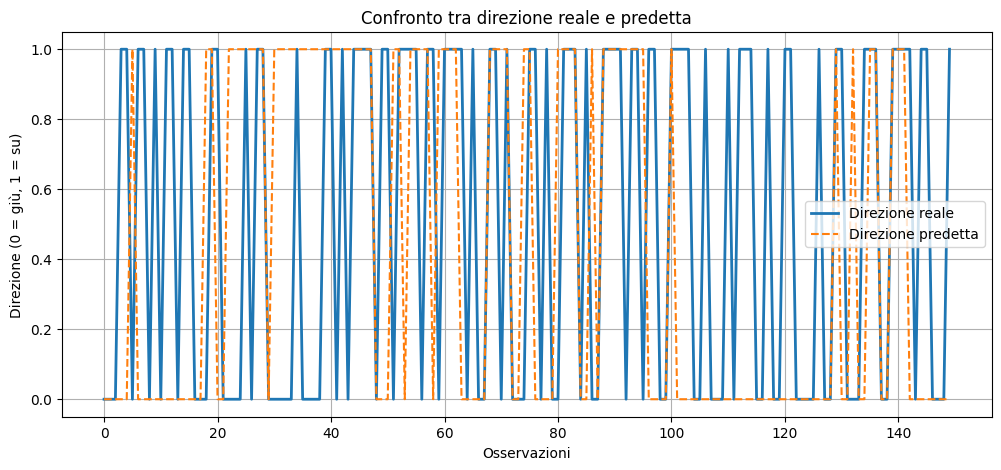

In [17]:
plt.figure(figsize=(12,5))

plt.plot(y_test.values[:150], label="Direzione reale", linewidth=2)
plt.plot(rf_pred[:150], label="Direzione predetta", linestyle="--")

plt.title("Confronto tra direzione reale e predetta")
plt.xlabel("Osservazioni")
plt.ylabel("Direzione (0 = giù, 1 = su)")

plt.legend()
plt.grid(True)

plt.show()

## Importanza delle feature - Random Forest

Momentum      0.133275
Volatility    0.130907
Volume        0.129594
MA50          0.115463
MA10          0.102891
Close         0.099166
Open          0.099081
High          0.098014
Low           0.091610
dtype: float64


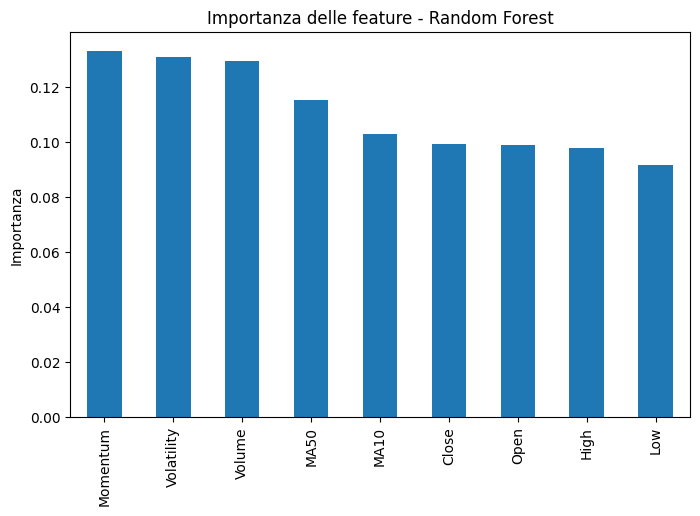

In [18]:
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

print(importances)

plt.figure(figsize=(8,5))
importances.plot(kind="bar")
plt.title("Importanza delle feature - Random Forest")
plt.ylabel("Importanza")
plt.show()

## Conclusioni

In questo modello ho applicato algoritmi di Machine Learning per predire la direzione del prezzo di un'azione utilizzando i dati storici.

Ho confrontato la Logistic Regression e Random Forest, osservando che Random Forest offre performance migliori.

Questo dimostra come il Machine Learning possa essere applicato all'analisi dei mercati finanziari, pur con alcune limitazioni
dovute alla natura complessa dei mercati.